In [1]:
from langgraph.graph import StateGraph ,START,END
from typing import List, Tuple, TypedDict, Any,Literal
from dotenv import load_dotenv


In [2]:
class QuardaticEquation(TypedDict):
    a:int
    b:int
    c:int

    equation: str
    descriminant: float
    result:float



In [3]:
def show_equation(state: QuardaticEquation) -> QuardaticEquation:
    equation=f'{state["a"]}x^2{state["b"]}x{state["c"]}'
    return {'equation':equation}


def calculate_discriminant(state: QuardaticEquation) -> QuardaticEquation:
   descriminant=state["b"]**2-(4*state["a"]*state["c"])
   return {"descriminant":descriminant}


def real_roots(state: QuardaticEquation) -> QuardaticEquation:
    root1= (-state["b"] + state["descriminant"]**0.5)/(2*state["a"])
    root2= (-state["b"] - state["descriminant"]**0.5)/(2*state["a"])
    result=f'The roots are {root1} and {root2}'
    return {"result":result}




def repeated_roots(state: QuardaticEquation) -> QuardaticEquation:
    root= (-state["b"])/(2*state["a"])
    result=f'The only repeating root is {root}'
    return {"result":result}

    
def unreal_root(state: QuardaticEquation) -> QuardaticEquation:
    result=f'No real roots'
    return {"result":result}


def checkcondition(state: QuardaticEquation) -> Literal["real_roots","repeated_roots","unreal_root"]:
    if state["descriminant"]>0:
        return "real_roots"
    elif state["descriminant"]==0:
        return "repeated_roots"
    else:
        return "unreal_root"


In [4]:
graph = StateGraph(QuardaticEquation)

graph.add_node('show_equation', show_equation, description="This node will show the equation in the form of ax^2 + bx + c = 0")
graph.add_node('calculate_discriminant', calculate_discriminant, description="This node will calculate the discriminant of the equation")
# graph.add_node('calculate_result', calculate_result, description="This node will calculate the result of the equation based on the discriminant")
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('unreal_root', unreal_root)


In [5]:
graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_discriminant')
graph.add_conditional_edges('calculate_discriminant', checkcondition)
graph.add_edge('real_roots',END)
graph.add_edge('repeated_roots',END)
graph.add_edge('unreal_root',END)


workflow=graph.compile()

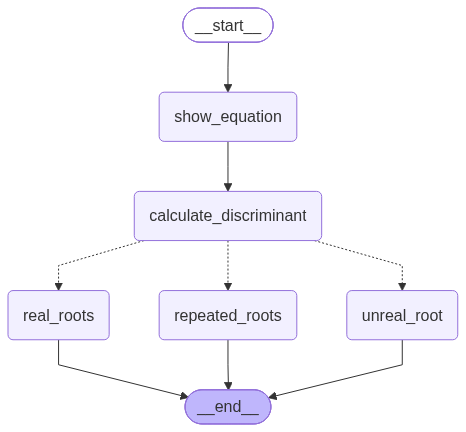

In [6]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [7]:
initial_state={
    'a':1,
    'b':-6,
    'c':9
}
workflow.invoke(initial_state)

{'a': 1,
 'b': -6,
 'c': 9,
 'equation': '1x^2-6x9',
 'descriminant': 0,
 'result': 'The only repeating root is 3.0'}